# [1] 10 The next-event forecast and the rainfall conditioning

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. The forecast mixture takes ~5 min.
```

**What this notebook does.** Everything the paper predicts is here, in one
place, from the event catalogues (04, 08) and the rain table (09):

1. **Renewal forecast** of the next onset: onsets drawn uniformly within
   their windows (no midpoints), intervals fitted by exponential, lognormal,
   Weibull, BPT and Gaussian models with a parametric bootstrap, conditional
   on no event by the reference date. Four catalogues: InSAR only, the
   dense-era array record (with and without the Loma Prieta interval), and
   the merged record. The forecast is conditioned on no event through the
   last InSAR acquisition (read from the data), so the numbers reproduce.
   The InSAR clock is also given in closed form (mean interval, t-based
   prediction interval), the numbers the text quotes. Fig 4.
2. **Rainfall conditioning**: for each onset, the water-year rain accumulated
   by then, the lag after fixed cumulative thresholds (rule A) and after the
   first storm of the year (rule B), and the storm-proximity test (rule C)
   scored against its wet-season base rate.
3. **The prediction statement**, combining the recurrence window with the
   calendar window.

Ported from `Hayward_DISP-S1/analysis/run21_recurrence_forecast.py` and
`run22_precip_conditioning.py`; until 2026-09-24 this was the second half of
notebook 09.

**Outputs** (`outputs/10_forecast/`): `recurrence_forecast_models.csv`,
`precip_conditioning_{events,thresholds,ruleC}.csv`, `prediction_statement.txt`,
`10_forecast_stats.txt`, registry rows `10_*`.

**What to check.** InSAR onsets fall Dec 13 to Mar 9; the InSAR clock gives
the next event about mid December 2026 with a 95% prediction interval of
late August 2026 to early April 2027; the array record gives ~28% for the
same wet season. Rule C: a 40 mm storm within 21 d of all five onsets. The
CHECK cell compares every product with the previous run.

In [1]:
# [2]
import os
from datetime import datetime

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
from scipy import stats                          # the renewal distributions
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

## [3] Paths and parameters

In [2]:
# [4]
notebook = "10_forecast"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version (09_seasonality_forecast), for the CHECK cell

# the forecast
loma_prieta = 1989.80
n_timing, n_boot, seed = 400, 5, 7          # timing draws x bootstrap refits per (catalogue, model, reference date)
# The forecast is conditioned on no event through the last date the data can vouch for: the end of the
# fault-parallel series, the earlier of the two tracks' last acquisitions (read from the data below).
# forecast_issue_date is only the date the statement was written; nothing verifies the months between
# the two, so nothing is claimed for them.
wet = ("2026-10-01", "2027-04-30")      # the coming wet season, WY2027
horizon = "2027-12-31"
models = ["exponential", "lognormal", "weibull", "bpt", "gaussian"]
grid = np.arange(2025.0, 2031.0, 1 / 365.25)   # the time axis of the forecast curves (daily)
resolvable_days = 130      # array windows longer than this do not constrain the season (as 09)

# the conditioning
y_grid = [50, 75, 100, 125, 150, 175, 200, 250, 300, 400]   # WY cumulative thresholds, mm (rule A)
z_grid = [15, 20, 25, 30, 40, 50, 75]                       # first-storm sizes (3-day totals), mm (rule B)
storm_days = 3
c_z, c_x = [20, 30, 40, 50], [7, 14, 21, 30]                # rule C storm size and lag
wy_years = (1980, 2026)
wet_dowy = (62, 182)               # Dec 1 to Mar 31 as day of water year

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["08_alignment_arrays"], "hrkt_aa_events.csv")
rain_file = os.path.join(paths_out["09_rain_seasonality"], "tulepond_daily_precip.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, events_file, aa_events_file, rain_file)

Registry for 10_forecast: run 6a5ea516, git 5952336+


## [5] Functions: dates and water years

In [3]:
# [6]
def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    dates = pd.DatetimeIndex(dates)
    year_start = pd.to_datetime(dates.year.astype(str) + "-01-01")
    next_year_start = pd.to_datetime((dates.year + 1).astype(str) + "-01-01")
    return dates.year + (dates - year_start) / (next_year_start - year_start)


def decyear_to_date(years):
    """Inverse of decyear, as a DatetimeIndex."""
    out = []
    for value in np.atleast_1d(np.asarray(years, float)):
        year = int(np.floor(value))
        year_start, next_year_start = datetime(year, 1, 1), datetime(year + 1, 1, 1)
        out.append(year_start + (value - year) * (next_year_start - year_start))
    return pd.DatetimeIndex(out)


def ymd(year):
    """One decimal year as 'YYYY-MM-DD'."""
    return decyear_to_date(year)[0].strftime("%Y-%m-%d")


def dowy_of(date):
    """(day of water year, water year) of one Timestamp; Oct 1 = 1."""
    wy = date.year + (1 if date.month >= 10 else 0)
    return (date - pd.Timestamp(f"{wy - 1}-10-01")).days + 1, wy


def dowy_label(day):
    """A day of water year as 'Mon DD' ('--' if undefined)."""
    if not np.isfinite(day):
        return "--"
    return (pd.Timestamp("2000-10-01") + pd.Timedelta(days=int(day) - 1)).strftime("%b %d")

## [7] Load: the rain table and the event catalogues

The rain table is notebook 09's composite (one value per day, Fremont >
Newark > Hayward). The catalogues: InSAR events from 04; the HRKT array
events from 08, of which the dense-era ones (windows of 130 d or less)
resolve the season; and the merged record, the dense-era array events and the
InSAR events, with the annual-survey years 2006 to 2017 treated as unobserved:
no interval is formed across them, the clock simply restarts with the first
InSAR detection. Array detections after 2006 enter no catalogue.

In [4]:
# [8]
rain = pd.read_csv(rain_file, index_col="date", parse_dates=True)
print(f"rain table: {len(rain)} days {rain.index[0].date()} to {rain.index[-1].date()}, columns {list(rain.columns)}")

creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_yr").reset_index(drop=True)
aa_events = pd.read_csv(aa_events_file)
aa_dense = aa_events[aa_events.window_days <= resolvable_days].reset_index(drop=True)
# every catalogue carries a `src` column; an interval is only formed between two events of the same source, so the
# merged catalogue never bridges 2006 to 2017, when the arrays were surveyed annually and the section was unobserved
# by the clock's standard (Dani, 2026-09-24). The clock restarts with the first InSAR detection.
insar_events = insar_events.assign(src="InSAR")
aa_dense = aa_dense.assign(src="AA")
merged_events = pd.concat([aa_dense[["onset_yr", "onset_lo", "onset_hi", "src"]], insar_events[["onset_yr", "onset_lo", "onset_hi", "src"]]])
merged_events = merged_events.sort_values("onset_yr").reset_index(drop=True)
# name -> (catalogue, drop the Loma Prieta-spanning interval?)
catalogues = {"A_insar": (insar_events, False), "B_aa_dense": (aa_dense, False), "B_aa_dense_noLP": (aa_dense, True), "C_merged": (merged_events, True)}   # the combined record also leaves out the Loma Prieta-spanning interval (Dani, 2026-09-29)
print(f"InSAR {len(insar_events)} events; array dense era {len(aa_dense)} events (windows <= {resolvable_days} d); "
      f"merged {len(merged_events)} events with 2006 to 2017 unobserved")

# the last date the data vouch for: the end of the fault-parallel series (03), i.e. the last acquisition seen by both tracks
data_end_yr = float(pd.read_csv(fp_ts_file, index_col=0, nrows=1).columns.astype(float).max())
data_end = (decyear_to_date(data_end_yr)[0] + pd.Timedelta(hours=12)).strftime("%Y-%m-%d")     # the columns are decimal years to 4 places: round to the day
ref_dates = {"data_end": data_end}
print(f"forecast conditioned on no event through {data_end} (the last InSAR acquisition on both tracks); statement written {forecast_issue_date}")

rain table: 17496 days 1978-10-01 to 2026-08-25, columns ['FREMONT', 'NEWARK', 'HAYWARD_AT', 'prcp_mm', 'src', 'decyear', 'wy', 'dowy']
InSAR 5 events; array dense era 9 events (windows <= 130 d); merged 14 events with 2006 to 2017 unobserved
forecast conditioned on no event through 2026-03-21 (the last InSAR acquisition on both tracks); statement written 2026-08-25


## [9] Renewal-model forecast of the next onset

For each catalogue: onsets drawn uniformly in their windows (400 draws), the
intervals fitted by each model, and for each fit a parametric bootstrap (5
refits) of the conditional next-onset distribution given no event by the
reference date. The quantiles and wet-season probabilities are the mixture
over all of them. Model families are compared by AICc on the median draw.

One random-number generator (`seed`) feeds every draw in order, so the
forecast reproduces exactly.

In [5]:
# [10]
def fit_interval_model(model, intervals):
    """The fitted scipy distribution of one renewal model to a set of intervals (yr)."""
    intervals = np.asarray(intervals, float)
    if model == "exponential":                    # Poisson process: memoryless
        return stats.expon(scale=intervals.mean())
    if model == "lognormal":
        log_intervals = np.log(intervals)
        return stats.lognorm(s=max(log_intervals.std(), 1e-3), scale=np.exp(log_intervals.mean()))
    if model == "weibull":
        shape, _, scale = stats.weibull_min.fit(intervals, floc=0, f0=None)
        return stats.weibull_min(c=shape, scale=scale)
    if model == "bpt":                            # Brownian passage time = inverse Gaussian
        mean = intervals.mean()
        alpha2 = max(mean * np.mean(1 / intervals - 1 / mean), 1e-4)
        return stats.invgauss(mu=alpha2, scale=mean / alpha2)
    if model == "gaussian":
        return stats.norm(loc=intervals.mean(), scale=max(intervals.std(ddof=1), 1e-3))
    raise ValueError(model)


def aicc(model, intervals):
    """Corrected Akaike information criterion of one model on the intervals, and its log-likelihood."""
    dist = fit_interval_model(model, intervals)
    loglike = dist.logpdf(intervals).sum()
    n_param, n = (1 if model == "exponential" else 2), len(intervals)
    correction = 2 * n_param * (n_param + 1) / (n - n_param - 1) if n - n_param - 1 > 0 else np.inf
    return -2 * loglike + 2 * n_param + correction, loglike


def interval_mask(onsets_sorted, src, drop_lp):
    """Which consecutive pairs of sorted onsets form a repeat interval: both from the same source (no interval
    bridges the unobserved 2006 to 2017 gap) and, if drop_lp, not spanning Loma Prieta."""
    keep = np.ones(len(onsets_sorted) - 1, bool)
    if src is not None:
        keep &= np.asarray(src)[:-1] == np.asarray(src)[1:]
    if drop_lp:
        keep &= ~((onsets_sorted[:-1] < loma_prieta) & (onsets_sorted[1:] > loma_prieta))
    return keep


def intervals_from(onsets, src=None, drop_lp=False):
    """Repeat intervals between sorted onsets (see interval_mask)."""
    order = np.argsort(onsets)
    onsets_sorted = np.asarray(onsets)[order]
    src_sorted = None if src is None else np.asarray(src)[order]
    return np.diff(onsets_sorted)[interval_mask(onsets_sorted, src_sorted, drop_lp)]


def conditional_cdf(dist, t_last, time_since_last):
    """P(next onset by t | no onset in the time_since_last after t_last), on the grid."""
    survival = dist.sf(time_since_last)
    if not np.isfinite(survival) or survival <= 0:
        return np.ones_like(grid)
    cdf = (dist.cdf(grid - t_last) - dist.cdf(time_since_last)) / survival
    return np.clip(np.where(grid - t_last > time_since_last, cdf, 0.0), 0, 1)


def forecast(model, catalogue, drop_lp, t_last_window, ref_yr, rng):
    """Mixture forecast for one model and catalogue: n_timing draws of the onsets in their windows,
    each fitted and bootstrapped n_boot times. Returns (mean conditional cdf on the grid, mean interval, mean CoV)."""
    cdf_sum = np.zeros_like(grid)
    n_curves = 0
    interval_means, interval_covs = [], []
    for _ in range(n_timing):
        # 1) one realisation of the onsets, uniform in their windows, and its intervals
        intervals = intervals_from(rng.uniform(catalogue.onset_lo.values, catalogue.onset_hi.values), catalogue.src.values, drop_lp)
        # 2) the model fitted to those intervals
        fitted_dist = fit_interval_model(model, intervals)
        interval_means.append(fitted_dist.mean())
        interval_covs.append(np.sqrt(fitted_dist.var()) / fitted_dist.mean())
        # 3) the last onset, uniform in its window, and how long ago it was at the reference date
        t_last = rng.uniform(*t_last_window)
        time_since_last = ref_yr - t_last
        # 4) parametric bootstrap: refit to synthetic intervals from the fitted model, forecast from each refit
        for _ in range(n_boot):
            bootstrap_intervals = np.clip(fitted_dist.rvs(size=len(intervals), random_state=rng), 0.05, None)
            cdf_sum += conditional_cdf(fit_interval_model(model, bootstrap_intervals), t_last, time_since_last)
            n_curves += 1
    return cdf_sum / n_curves, float(np.mean(interval_means)), float(np.mean(interval_covs))


def quantile_date(cdf, q):
    """The grid date at which the cdf first reaches q."""
    return grid[min(np.searchsorted(cdf, q), len(grid) - 1)]


def prob_between(cdf, date_a, date_b):
    """P(onset between two calendar dates) from a cdf on the grid."""
    year_a, year_b = decyear(pd.to_datetime([date_a, date_b]))
    return float(np.interp(year_b, grid, cdf) - np.interp(year_a, grid, cdf))

## [11] The five renewal models, one at a time

Before the mixture, each model on its own, fitted once by maximum likelihood
to the midpoint intervals of catalogue A (the five InSAR events, 4 intervals)
and of catalogue B (the dense-era array events, 8 intervals). The forecast
below never uses these single fits (it draws the onsets within their windows
and bootstraps), but they show what each family assumes and what it would
say. The number to compare is P(onset in the WY2027 wet season | no onset by
the data end). `describe_fit` prints the same lines for every model.

In [6]:
# [12]
insar_intervals = intervals_from(insar_events.onset_yr.values)          # midpoints, for illustration only
array_intervals = intervals_from(aa_dense.onset_yr.values)
last_onset_yr = float(insar_events.onset_yr.iloc[-1])
time_since_last_yr = data_end_yr - last_onset_yr
print(f"InSAR intervals (yr): {np.round(insar_intervals, 2)}; array intervals (yr): {np.round(array_intervals, 2)}")
print(f"data end {data_end} = {data_end_yr:.3f}; last onset {last_onset_yr:.3f}; {time_since_last_yr:.2f} yr elapsed with no event")


def describe_fit(model, intervals, label):
    """One maximum-likelihood fit: mean, CoV, the family's own parameters, AICc, and the conditional
    wet-season probability. Returns the fitted distribution."""
    dist = fit_interval_model(model, intervals)
    aicc_value, loglike = aicc(model, intervals)
    cdf = conditional_cdf(dist, last_onset_yr, time_since_last_yr)
    p_wet = prob_between(cdf, *wet)
    if model == "exponential":
        own = f"rate {1 / dist.mean():.2f} /yr"
    elif model == "lognormal":
        own = f"median {dist.median():.2f} yr, sigma_log {dist.kwds['s']:.2f}"
    elif model == "weibull":
        own = f"shape k {dist.kwds['c']:.2f}, scale {dist.kwds['scale']:.2f} yr"
    elif model == "bpt":
        own = f"aperiodicity alpha {np.sqrt(dist.kwds['mu']):.2f}"
    else:
        own = f"sd {np.sqrt(dist.var()) * 365.25:.0f} d"
    print(f"  {label:<8} {model:<12} mean {dist.mean():.2f} yr, CoV {np.sqrt(dist.var()) / dist.mean():.2f}, {own}; "
          f"AICc {aicc_value:6.1f}; P(WY2027 wet season | quiet to data end) {p_wet:.2f}; "
          f"5-50-95% {ymd(quantile_date(cdf, 0.05))} {ymd(quantile_date(cdf, 0.5))} {ymd(quantile_date(cdf, 0.95))}")
    return dist


single_fits = {}          # (catalogue, model) -> fitted distribution, for the comparison figure

InSAR intervals (yr): [2.09 1.92 1.97 1.9 ]; array intervals (yr): [2.85 2.28 4.91 4.13 2.75 2.8  2.14 0.88]
data end 2026-03-21 = 2026.216; last onset 2024.984; 1.23 yr elapsed with no event


### [13] Exponential: the Poisson null

One parameter, the mean interval. The hazard rate (the chance of an onset in
the next instant, given none yet) is constant: the fault has no memory of
when it last slipped, so the elapsed 1.7 yr since the 2024.98 event changes
nothing. This is the "no clock" null every time-dependent forecast is
measured against (WGCEP 1988; Ellsworth et al. 1999). With a mean of 2 yr it
gives roughly a 25 % chance of an onset in any given half-year, whenever
that half-year is.

In [7]:
# [14]
print("exponential")
single_fits[("A", "exponential")] = describe_fit("exponential", insar_intervals, "A InSAR")
single_fits[("B", "exponential")] = describe_fit("exponential", array_intervals, "B array")

exponential
  A InSAR  exponential  mean 1.97 yr, CoV 1.00, rate 0.51 /yr; AICc   17.4; P(WY2027 wet season | quiet to data end) 0.19; 5-50-95% 2026-04-27 2027-08-02 2030-12-31
  B array  exponential  mean 2.84 yr, CoV 1.00, rate 0.35 /yr; AICc   35.4; P(WY2027 wet season | quiet to data end) 0.15; 5-50-95% 2026-05-13 2028-03-10 2030-12-31


### [15] Lognormal: the original time-dependent model

The logarithm of the interval is Gaussian: two parameters, the median
interval and the spread of the logarithm. The hazard rises after the last
event, peaks near the median, then FALLS for long elapsed times, so an event
that is very overdue is treated as less likely, not more. Nishenko and
Buland (1987) introduced it for earthquake recurrence and the first Working
Group on California Earthquake Probabilities (1988, 1990) used it.

In [8]:
# [16]
print("lognormal")
single_fits[("A", "lognormal")] = describe_fit("lognormal", insar_intervals, "A InSAR")
single_fits[("B", "lognormal")] = describe_fit("lognormal", array_intervals, "B array")

lognormal
  A InSAR  lognormal    mean 1.97 yr, CoV 0.04, median 1.97 yr, sigma_log 0.04; AICc    6.2; P(WY2027 wet season | quiet to data end) 1.00; 5-50-95% 2026-11-04 2026-12-15 2027-01-28
  B array  lognormal    mean 2.89 yr, CoV 0.51, median 2.57 yr, sigma_log 0.48; AICc   32.6; P(WY2027 wet season | quiet to data end) 0.22; 5-50-95% 2026-05-30 2027-08-29 2030-10-04


### [17] Weibull: the ageing model

Two parameters, a scale and a shape k. The hazard is a power of the elapsed
time, t to the (k - 1): k = 1 is the exponential, k > 1 means the chance
keeps rising the longer the fault waits (ageing, as in reliability
engineering, where the family comes from), without limit. Hagiwara (1974)
applied it to earthquakes; Utsu (1984) compared it with the others. A large
k is a very regular clock.

In [9]:
# [18]
print("weibull")
single_fits[("A", "weibull")] = describe_fit("weibull", insar_intervals, "A InSAR")
single_fits[("B", "weibull")] = describe_fit("weibull", array_intervals, "B array")

weibull
  A InSAR  weibull      mean 1.97 yr, CoV 0.05, shape k 26.77, scale 2.01 yr; AICc    7.2; P(WY2027 wet season | quiet to data end) 0.97; 5-50-95% 2026-10-13 2026-12-19 2027-01-29
  B array  weibull      mean 2.84 yr, CoV 0.40, shape k 2.67, scale 3.20 yr; AICc   31.1; P(WY2027 wet season | quiet to data end) 0.18; 5-50-95% 2026-06-22 2027-11-21 2029-11-10


### [19] Brownian passage time: the physical model

The inverse-Gaussian distribution of the first time a steadily loaded state
variable, perturbed by Brownian noise, reaches a fixed threshold (Matthews,
Ellsworth and Reasenberg 2002). Two parameters: the mean interval and the
aperiodicity alpha, which is the CoV of the intervals. The hazard rises
after the last event and then LEVELS OFF at a finite plateau, so an
overdue event stays about equally likely rather than certain or fading.
It is the standard of WGCEP 2003 and UCERF3 (Field et al. 2015) and the
model the prediction statement quotes.

In [10]:
# [20]
print("bpt")
single_fits[("A", "bpt")] = describe_fit("bpt", insar_intervals, "A InSAR")
single_fits[("B", "bpt")] = describe_fit("bpt", array_intervals, "B array")

bpt
  A InSAR  bpt          mean 1.97 yr, CoV 0.04, aperiodicity alpha 0.04; AICc    6.2; P(WY2027 wet season | quiet to data end) 1.00; 5-50-95% 2026-11-04 2026-12-15 2027-01-28
  B array  bpt          mean 2.84 yr, CoV 0.51, aperiodicity alpha 0.51; AICc   32.8; P(WY2027 wet season | quiet to data end) 0.22; 5-50-95% 2026-05-23 2027-08-12 2030-09-26


### [21] Gaussian: the plain clock

Mean and standard deviation of the intervals, the arithmetic the text
quotes (next = last + mean, plus or minus the sd). Not a recurrence model in
the forecasting literature: its hazard rises without bound and it allows
negative intervals in principle. It is here because with four intervals the
other families cannot be told apart, and the reader should see that the
plain clock says the same thing they do.

In [11]:
# [22]
print("gaussian")
single_fits[("A", "gaussian")] = describe_fit("gaussian", insar_intervals, "A InSAR")
single_fits[("B", "gaussian")] = describe_fit("gaussian", array_intervals, "B array")

gaussian
  A InSAR  gaussian     mean 1.97 yr, CoV 0.04, sd 30 d; AICc    6.4; P(WY2027 wet season | quiet to data end) 0.99; 5-50-95% 2026-10-27 2026-12-16 2027-02-03
  B array  gaussian     mean 2.84 yr, CoV 0.43, sd 450 d; AICc   31.4; P(WY2027 wet season | quiet to data end) 0.17; 5-50-95% 2026-07-03 2027-12-23 2029-11-29


### [23] The five side by side

Left: the interval density of each model fitted to the InSAR intervals, the
four intervals as ticks. Middle: the hazard rate, the chance of an onset per
year given none yet, against time since the last event; this is where the
families differ, and the dotted line marks where we are at the data end.
Right: the conditional forecast from each single fit, the wet season shaded.
The array fits are the thin lines.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/qc10_renewal_models_single_fits.png


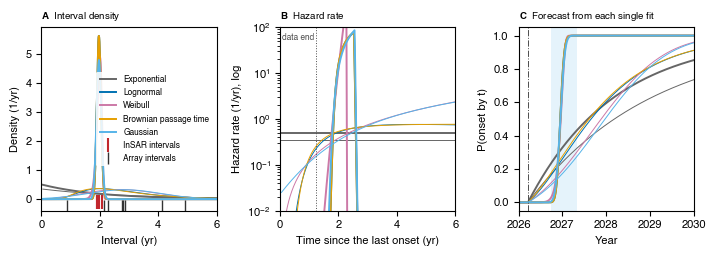

In [12]:
# [24]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt
model_colours = {"exponential": "0.4", "lognormal": "#0072B2", "weibull": "#CC79A7", "bpt": "#E69F00", "gaussian": "#56B4E9"}   # Okabe-Ito, no green
model_names = {"exponential": "Exponential", "lognormal": "Lognormal", "weibull": "Weibull", "bpt": "Brownian passage time", "gaussian": "Gaussian"}
interval_axis = np.linspace(0.05, 6.0, 600)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6))
for model in models:
    for cat, lw in (("A", 1.4), ("B", 0.7)):
        dist = single_fits[(cat, model)]
        axes[0].plot(interval_axis, dist.pdf(interval_axis), color=model_colours[model], lw=lw, label=model_names[model] if cat == "A" else None)
        hazard = dist.pdf(interval_axis) / np.clip(dist.sf(interval_axis), 1e-12, None)
        axes[1].plot(interval_axis, hazard, color=model_colours[model], lw=lw)
        axes[2].plot(grid, conditional_cdf(dist, last_onset_yr, time_since_last_yr), color=model_colours[model], lw=lw)
axes[0].plot(insar_intervals, np.full_like(insar_intervals, -0.1), "|", color="#C1272D", ms=10, mew=1.5, label="InSAR intervals")
axes[0].plot(array_intervals, np.full_like(array_intervals, -0.25), "|", color="0.2", ms=8, mew=1.0, label="Array intervals")
axes[0].set_xlim(0, 6)
axes[0].set_ylim(-0.4, None)
axes[0].set_xlabel("Interval (yr)")
axes[0].set_ylabel("Density (1/yr)")
utils.panel_title(axes[0], "A", "Interval density")
axes[0].legend(fontsize=6)
axes[1].axvline(time_since_last_yr, color="0.3", lw=0.7, ls=":")
axes[1].text(time_since_last_yr - 0.05, 0.97, "data end", transform=axes[1].get_xaxis_transform(), fontsize=6, color="0.3", va="top", ha="right")
axes[1].set_xlim(0, 6)
axes[1].set_yscale("log")
axes[1].set_ylim(0.01, 100)
axes[1].set_xlabel("Time since the last onset (yr)")
axes[1].set_ylabel("Hazard rate (1/yr), log")
utils.panel_title(axes[1], "B", "Hazard rate")
axes[2].axvspan(*decyear(pd.to_datetime(list(wet))), color="#56B4E9", alpha=0.15, lw=0)
axes[2].axvline(data_end_yr, color="0.3", lw=0.7, ls="-.")
axes[2].set_xlim(2026.0, 2030.0)
axes[2].set_xlabel("Year")
axes[2].set_ylabel("P(onset by t)")
utils.panel_title(axes[2], "C", "Forecast from each single fit")
fig.tight_layout()
f_models = os.path.join(fig_dir, "qc10_renewal_models_single_fits.png")
fig.savefig(f_models, dpi=300)
fig.savefig(f_models.replace(".png", ".pdf"))
print("Saved figure to:", f_models)
plt.show()

## [25] The mixture forecast

Now the real thing: for each catalogue and model, 400 draws of the onsets
within their windows, each fitted and bootstrapped, conditioned on the two
reference dates.

In [13]:
# [26]
rng = np.random.default_rng(seed)
t_last_window = (float(insar_events.onset_lo.iloc[-1]), float(insar_events.onset_hi.iloc[-1]))
refs = {key: float(decyear(pd.to_datetime([date]))[0]) for key, date in ref_dates.items()}
forecast_rows = []
forecast_curves = {}
stats_lines = ["10 FORECAST AND RAINFALL CONDITIONING", "", "RENEWAL FORECAST",
               f"last event onset window {ymd(t_last_window[0])} to {ymd(t_last_window[1])}; reference dates " +
               ", ".join(f"{k} {v}" for k, v in ref_dates.items()) + f"; {n_timing} timing draws x {n_boot} bootstrap refits; "
               f"wet season {wet[0]}..{wet[1]}"]
for cat_name, (catalogue, drop_lp) in catalogues.items():
    # the spread of the intervals over the timing draws, and the AICc of each model on the median draw
    interval_draws = [intervals_from(rng.uniform(catalogue.onset_lo.values, catalogue.onset_hi.values), catalogue.src.values, drop_lp)
                      for _ in range(n_timing)]
    draw_means = np.array([draw.mean() for draw in interval_draws])
    draw_sds = np.array([draw.std(ddof=1) for draw in interval_draws])
    median_draw = interval_draws[int(np.argsort(draw_means)[len(draw_means) // 2])]
    aicc_by_model = {model: aicc(model, median_draw) for model in models}
    best_model = min(aicc_by_model, key=lambda model: aicc_by_model[model][0])
    stats_lines += [f"{cat_name}: {len(catalogue)} events, {len(interval_draws[0])} intervals" + (" (Loma Prieta-spanning intervals dropped)" if drop_lp else ""),
                    f"  interval mean {draw_means.mean():.2f} yr, sd {draw_sds.mean():.2f} yr, CoV {np.mean(draw_sds / draw_means):.2f}; AICc: " +
                    ", ".join(f"{model} {aicc_by_model[model][0]:.1f}" for model in models)]
    for model in models:
        for ref_key, ref_yr in refs.items():
            cdf, interval_mean, interval_cov = forecast(model, catalogue, drop_lp, t_last_window, ref_yr, rng)
            forecast_curves[(cat_name, model, ref_key)] = cdf
            quantiles = {p: quantile_date(cdf, p) for p in (0.05, 0.5, 0.95)}
            row = dict(catalog=cat_name, model=model, ref=ref_key, ref_date=ref_dates[ref_key], n_intervals=len(interval_draws[0]),
                       mean_yr=interval_mean, cov=interval_cov,
                       aicc=aicc_by_model[model][0], daicc=aicc_by_model[model][0] - aicc_by_model[best_model][0],
                       q05=ymd(quantiles[0.05]), q50=ymd(quantiles[0.5]), q95=ymd(quantiles[0.95]),
                       p_wet_season=prob_between(cdf, *wet),
                       p_by_2027=float(np.interp(decyear(pd.to_datetime([horizon]))[0], grid, cdf)),
                       p_within_1yr=float(np.interp(ref_yr + 1, grid, cdf)))
            forecast_rows.append(row)
            if ref_key == "data_end":
                stats_lines.append(f"    {model:<12} mean {interval_mean:.2f} yr CoV {interval_cov:.2f} | next onset 5-50-95%: "
                                   f"{row['q05']} {row['q50']} {row['q95']} | P(wet season WY2027) {row['p_wet_season']:.2f}  "
                                   f"P(by end 2027) {row['p_by_2027']:.2f}")
forecasts = pd.DataFrame(forecast_rows)
forecasts.to_csv(os.path.join(out_dir, "recurrence_forecast_models.csv"), index=False, float_format="%.3f")
print("\n".join(stats_lines))

/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:2766: RuntimeWarning: overflow encountered in power
  return -sc.expm1(-pow(x, c))


10 FORECAST AND RAINFALL CONDITIONING

RENEWAL FORECAST
last event onset window 2024-12-13 to 2024-12-25; reference dates data_end 2026-03-21; 400 timing draws x 5 bootstrap refits; wet season 2026-10-01..2027-04-30
A_insar: 5 events, 4 intervals
  interval mean 1.97 yr, sd 0.08 yr, CoV 0.04; AICc: exponential 17.4, lognormal 6.8, weibull 7.9, bpt 6.8, gaussian 7.1
    exponential  mean 1.97 yr CoV 1.00 | next onset 5-50-95%: 2026-04-18 2027-05-20 2030-12-31 | P(wet season WY2027) 0.20  P(by end 2027) 0.64
    lognormal    mean 1.97 yr CoV 0.04 | next onset 5-50-95%: 2026-10-28 2026-12-08 2027-01-20 | P(wet season WY2027) 0.99  P(by end 2027) 1.00
    weibull      mean 1.97 yr CoV 0.05 | next onset 5-50-95%: 2026-10-06 2026-12-13 2027-01-23 | P(wet season WY2027) 0.96  P(by end 2027) 1.00
    bpt          mean 1.97 yr CoV 0.04 | next onset 5-50-95%: 2026-10-28 2026-12-08 2027-01-21 | P(wet season WY2027) 0.99  P(by end 2027) 1.00
    gaussian     mean 1.97 yr CoV 0.04 | next onset 5-50

## [27] The InSAR clock in closed form

The plain arithmetic the text quotes: mean and sd of the four intervals
between the five midpoint onsets, next = last + mean, and a t-based 95%
prediction interval for a single new draw.

In [14]:
# [28]
clock_intervals = np.diff(insar_events.onset_yr.values)
n_intervals = len(clock_intervals)
interval_mean_yr = clock_intervals.mean()
interval_sd_yr = clock_intervals.std(ddof=1)
t_critical = stats.t.ppf(0.975, n_intervals - 1)
half_width_yr = t_critical * interval_sd_yr * np.sqrt(1 + 1 / n_intervals)          # 95% prediction interval half-width
next_onset_yr = float(insar_events.onset_yr.iloc[-1]) + interval_mean_yr
sd_ci_days = (interval_sd_yr * np.sqrt((n_intervals - 1) / stats.chi2.ppf(.975, n_intervals - 1)) * 365.25,
              interval_sd_yr * np.sqrt((n_intervals - 1) / stats.chi2.ppf(.025, n_intervals - 1)) * 365.25)
clock_lines = ["InSAR clock, closed form: intervals " + ", ".join(f"{v:.2f}" for v in clock_intervals) +
               f" yr; mean {interval_mean_yr:.3f} yr, sd {interval_sd_yr * 365.25:.0f} d (95% CI {sd_ci_days[0]:.0f}-{sd_ci_days[1]:.0f} d), "
               f"CoV {interval_sd_yr / interval_mean_yr:.3f}",
               f"  next = last + mean = {next_onset_yr:.3f} ({ymd(next_onset_yr)}); +/-1 sd {ymd(next_onset_yr - interval_sd_yr)}..{ymd(next_onset_yr + interval_sd_yr)}; "
               f"95% prediction interval (t, n={n_intervals}) {ymd(next_onset_yr - half_width_yr)}..{ymd(next_onset_yr + half_width_yr)}"]
stats_lines += clock_lines
print("\n".join(clock_lines))

InSAR clock, closed form: intervals 2.09, 1.92, 1.97, 1.90 yr; mean 1.971 yr, sd 30 d (95% CI 17-113 d), CoV 0.042
  next = last + mean = 2026.955 (2026-12-15); +/-1 sd 2026-11-15..2027-01-14; 95% prediction interval (t, n=4) 2026-08-29..2027-04-02


## [29] Figure 4: the repeat intervals and the next-onset forecast

A) the intervals of the three catalogues the text quotes; the array record and
the combined record leave out the interval spanning the 1989 Loma Prieta
earthquake (Dani, 2026-09-29: the text says so explicitly; the array record
with it, B, stays in the table). B) the conditional probability
of the next onset from the BPT model of each catalogue, one line each, the
2026-27 wet season shaded.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved Fig 4 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/fig4_recurrence_forecast_ntiming400_nboot5_issue2026-08-25.png


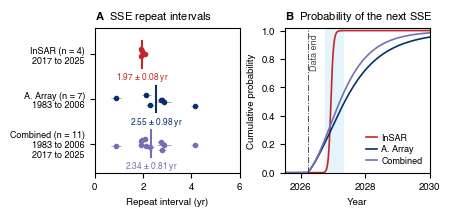

In [15]:
# [30]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
shown = ["A_insar", "B_aa_dense_noLP", "C_merged"]       # the array without the Loma Prieta interval; B (with it) stays in the table
colours = {"A_insar": "#C1272D", "B_aa_dense_noLP": "#08306B", "C_merged": "#7570B3"}
labels = {"A_insar": "InSAR", "B_aa_dense_noLP": "A. Array", "C_merged": "Combined"}
spans = {"A_insar": "2017 to 2025", "B_aa_dense_noLP": "1983 to 2006", "C_merged": "1983 to 2006\n2017 to 2025"}
label_pt = 7
# 1.5-column width (4.72 in); the two panels are placed by hand so they are the same square, whatever the label widths
fig_w, fig_h, box = 4.72, 2.20, 1.45                # inches: figure, and the side of each panel
fig = plt.figure(figsize=(fig_w, fig_h))
axes = [fig.add_axes([1.05 / fig_w, 0.45 / fig_h, box / fig_w, box / fig_h]),      # A: room on the left for its tick labels
        fig.add_axes([2.95 / fig_w, 0.45 / fig_h, box / fig_w, box / fig_h])]      # B: room on the right for its title and last tick
for ax in axes:
    ax.tick_params(labelsize=label_pt)

# A) the repeat intervals of each catalogue with their window uncertainty; the bar is the mean, written under it with the sd
ax = axes[0]
tick_labels = []
for j, cat_name in enumerate(shown):
    catalogue, drop_lp = catalogues[cat_name]
    onsets = catalogue.onset_yr.values
    keep = interval_mask(onsets, catalogue.src.values, drop_lp)
    intervals = np.diff(onsets)[keep]
    window_err = (0.5 * ((catalogue.onset_hi - catalogue.onset_lo).values[1:] + (catalogue.onset_hi - catalogue.onset_lo).values[:-1]))[keep]
    ax.errorbar(intervals, j + rng.uniform(-0.15, 0.15, len(intervals)), xerr=window_err, fmt="o", ms=3.0, color=colours[cat_name], ecolor="0.6", elinewidth=0.6)
    ax.plot([np.mean(intervals)] * 2, [j - 0.3, j + 0.3], "-", color=colours[cat_name], lw=1.5)
    ax.text(np.mean(intervals), j + 0.36, f"{np.mean(intervals):.2f} $\\pm$ {np.std(intervals, ddof=1):.2f} yr", ha="center", va="top",
            fontsize=6, color=colours[cat_name])
    tick_labels.append(f"{labels[cat_name]} (n = {len(intervals)})\n{spans[cat_name]}")
ax.set_yticks(range(len(shown)))
ax.set_yticklabels(tick_labels, fontsize=6.5, linespacing=1.1)
ax.set_ylim(len(shown) - 0.35, -0.6)          # inverted: first catalogue on top; room under the last bar for its number
ax.set_xlim(0, 6)
ax.set_xlabel("Repeat interval (yr)", fontsize=label_pt)
ax.set_title(r"$\bf{A}$  SSE repeat intervals", loc="left", fontsize=8)

# B) the conditional forecast, BPT, one line per catalogue; the wet season shaded, the data end marked
ax = axes[1]
wet_years = decyear(pd.to_datetime(list(wet)))
ax.axvspan(wet_years[0], wet_years[1], color="#56B4E9", alpha=0.15, lw=0)
for cat_name in shown:
    ax.plot(grid, forecast_curves[(cat_name, "bpt", "data_end")], "-", color=colours[cat_name], lw=1.2, label=labels[cat_name])
ax.axvline(refs["data_end"], color="0.3", lw=0.7, ls="-.")
ax.text(refs["data_end"] + 0.06, 0.98, "Data end", fontsize=6.5, color="0.3", va="top", ha="left", rotation=90)
ax.set_xlim(2025.5, 2030.0)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Cumulative probability", fontsize=label_pt)
ax.set_title(r"$\bf{B}$  Probability of the next SSE", loc="left", fontsize=8)
ax.legend(fontsize=6.5, loc="lower right", handlelength=1.2, handletextpad=0.5, borderpad=0.3, labelspacing=0.3,
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
f_forecast = os.path.join(fig_dir, f"fig4_recurrence_forecast_ntiming{n_timing}_nboot{n_boot}_issue{forecast_issue_date}.png")
fig.savefig(f_forecast, dpi=300)
fig.savefig(f_forecast.replace(".png", ".pdf"))
print("Saved Fig 4 to:", f_forecast)
plt.show()

## [31] Rainfall conditioning of the onset timing

Every quantity is a range over the onset window (the event is equally likely
anywhere in it). Rule A: lag after the water-year cumulative first exceeds
Y mm. Rule B: lag after the first 3-day storm of at least Z mm. Rule C: a
3-day storm of at least Z mm ended within X days before some day of the
window, scored against the fraction of wet-season days such a window covers,
so five hits out of five can be weighed against chance. The calendar spread
of the InSAR onsets is the baseline any rule has to beat.

In [16]:
# [32]
def wy_series(wy):
    """One water year of the daily rain with its cumulative total and running 3-day storm total."""
    this_year = rain[rain.wy == wy].copy()
    this_year["cum"] = this_year.prcp_mm.fillna(0).cumsum()
    this_year["storm"] = this_year.prcp_mm.fillna(0).rolling(storm_days, min_periods=1).sum()
    return this_year


def first_date(this_year, column, threshold):
    """The first day of the water year on which `column` reaches `threshold` (NaT if never)."""
    hits = this_year.index[this_year[column] >= threshold]
    return hits[0] if len(hits) else pd.NaT


# antecedent rain at every day: 30-day total, largest 3-day storm in 30 days, days since the last >= 20 mm storm
rain_daily = rain.prcp_mm.fillna(0)
storm_3d = rain_daily.rolling(storm_days, min_periods=1).sum()
antecedent = pd.DataFrame(index=rain.index)
antecedent["rain_30d"] = rain_daily.rolling(30, min_periods=1).sum()
antecedent["max_storm_30d"] = storm_3d.rolling(30, min_periods=1).max()
last_storm_day = pd.Series(np.where(storm_3d >= 20, np.arange(len(rain)), np.nan), index=rain.index).ffill()
antecedent["days_since_storm20"] = np.arange(len(rain)) - last_storm_day

# per event (array dense era + InSAR): the rain state over its onset window, and the lags after each rule A / rule B threshold
events = pd.concat([aa_dense[["onset_lo", "onset_hi"]].assign(source="AA"), insar_events[["onset_lo", "onset_hi"]].assign(source="InSAR")])
events = events.sort_values("onset_lo").reset_index(drop=True)
event_rows = []
for event in events.itertuples():
    date_lo, date_hi = decyear_to_date(event.onset_lo)[0], decyear_to_date(event.onset_hi)[0]
    _, wy = dowy_of(date_hi)
    this_year = wy_series(wy)
    row = dict(source=event.source, onset_lo=date_lo.date(), onset_hi=date_hi.date(), window_days=(date_hi - date_lo).days, wy=wy,
               dowy_lo=dowy_of(date_lo)[0], dowy_hi=dowy_of(date_hi)[0], wy_total_mm=float(this_year.cum.iloc[-1]),
               cum_at_lo=float(this_year.cum.asof(date_lo)) if date_lo >= this_year.index[0] else 0.0,
               cum_at_hi=float(this_year.cum.asof(date_hi)), gauge=this_year.src.mode().iloc[0])
    row["frac_at_hi"] = row["cum_at_hi"] / row["wy_total_mm"]
    window_antecedent = antecedent.loc[date_lo:date_hi]
    for column in ("rain_30d", "max_storm_30d", "days_since_storm20"):
        row[f"{column}_min"] = float(window_antecedent[column].min())
        row[f"{column}_max"] = float(window_antecedent[column].max())
    for Y in y_grid:
        crossing = first_date(this_year, "cum", Y)
        row[f"lagY{Y}_lo"] = (date_lo - crossing).days if pd.notna(crossing) else np.nan
        row[f"lagY{Y}_hi"] = (date_hi - crossing).days if pd.notna(crossing) else np.nan
    for Z in z_grid:
        crossing = first_date(this_year, "storm", Z)
        row[f"lagZ{Z}_lo"] = (date_lo - crossing).days if pd.notna(crossing) else np.nan
        row[f"lagZ{Z}_hi"] = (date_hi - crossing).days if pd.notna(crossing) else np.nan
    event_rows.append(row)
event_rain = pd.DataFrame(event_rows)
event_rain.to_csv(os.path.join(out_dir, "precip_conditioning_events.csv"), index=False, float_format="%.1f")
insar_rain = event_rain[event_rain.source == "InSAR"]
aa_rain = event_rain[event_rain.source == "AA"]


def rule_scores(kind, thresholds):
    """Rules A (kind 'Y', WY cumulative) and B (kind 'Z', first storm): for each threshold, the InSAR lag range,
    how many array events are consistent with it, and when the threshold is typically crossed."""
    scores = []
    for threshold in thresholds:
        lag_lo, lag_hi = insar_rain[f"lag{kind}{threshold}_lo"], insar_rain[f"lag{kind}{threshold}_hi"]
        if lag_lo.isna().any():
            scores.append(dict(kind=kind, thr=threshold, n_insar_reached=int(lag_lo.notna().sum())))
            continue
        insar_lag_min, insar_lag_max = int(lag_lo.min()), int(lag_hi.max())
        aa_lag_lo, aa_lag_hi = aa_rain[f"lag{kind}{threshold}_lo"], aa_rain[f"lag{kind}{threshold}_hi"]
        reached = aa_lag_lo.notna()
        consistent = reached & (aa_lag_hi >= insar_lag_min) & (aa_lag_lo <= insar_lag_max)
        crossing_dowy = {}
        for wy in range(wy_years[0], wy_years[1] + 1):
            crossing = first_date(wy_series(wy), "cum" if kind == "Y" else "storm", threshold)
            crossing_dowy[wy] = dowy_of(crossing)[0] if pd.notna(crossing) else np.nan
        crossing_dowy = pd.Series(crossing_dowy)
        scores.append(dict(kind=kind, thr=threshold, n_insar_reached=5, insar_lag_min=insar_lag_min, insar_lag_max=insar_lag_max,
                           insar_lag_spread=insar_lag_max - insar_lag_min, aa_reached=int(reached.sum()), aa_consistent=int(consistent.sum()),
                           wy_reached_frac=float(crossing_dowy.notna().mean()), cross_dowy_median=float(crossing_dowy.median()),
                           cross_dowy_10=float(crossing_dowy.quantile(.1)), cross_dowy_90=float(crossing_dowy.quantile(.9))))
    return pd.DataFrame(scores)


threshold_scores = pd.concat([rule_scores("Y", y_grid), rule_scores("Z", z_grid)])
threshold_scores.to_csv(os.path.join(out_dir, "precip_conditioning_thresholds.csv"), index=False, float_format="%.2f")

# rule C: a >= Z mm 3-day storm ended within X d before some day of the window, against its wet-season base rate
wet_mask = (rain.dowy >= wet_dowy[0]) & (rain.dowy <= wet_dowy[1]) & (rain.wy >= wy_years[0])
rule_c_rows = []
for Z in c_z:
    for X in c_x:
        recent_storm = (storm_3d >= Z).rolling(X + 1, min_periods=1).max().astype(bool)     # True on days within X d after a >= Z storm
        hits = {event.Index: bool(recent_storm.loc[pd.Timestamp(event.onset_lo):pd.Timestamp(event.onset_hi)].any()) for event in event_rain.itertuples()}
        p_chance = 1.0
        for event in insar_rain.itertuples():
            # the chance a window this long, placed anywhere in that wet season, would contain such a day
            covered = recent_storm[rain.wy == event.wy].rolling(max(int(event.window_days), 1), min_periods=1).max().astype(bool)
            p_chance *= float(covered[wet_mask & (rain.wy == event.wy)].mean())
        rule_c_rows.append(dict(Z=Z, X=X, base_rate=float(recent_storm[wet_mask].mean()), insar_hits=sum(hits[i] for i in insar_rain.index),
                                aa_hits=sum(hits[i] for i in aa_rain.index), p_chance_all_insar=p_chance))
rule_c = pd.DataFrame(rule_c_rows)
rule_c.to_csv(os.path.join(out_dir, "precip_conditioning_ruleC.csv"), index=False, float_format="%.3f")

# the summary lines
calendar_spread = int(insar_rain.dowy_hi.max() - insar_rain.dowy_lo.min())
wy_total_series = rain.groupby("wy").prcp_mm.sum(min_count=1)
wy_total_series = wy_total_series[(wy_total_series.index >= wy_years[0]) & (wy_total_series.index <= 2025)]
conditioning_lines = ["", "RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)"]
for event in event_rain.itertuples():
    conditioning_lines.append(
        f"  {event.source:<5} {event.onset_lo}..{event.onset_hi} ({event.window_days:3d} d) WY{event.wy} total {event.wy_total_mm:5.0f} mm "
        f"(P{(wy_total_series < event.wy_total_mm).mean() * 100:2.0f}) | cum {event.cum_at_lo:4.0f}-{event.cum_at_hi:4.0f} mm, frac {event.frac_at_hi:.2f} | "
        f"rain 30 d {event.rain_30d_min:3.0f}-{event.rain_30d_max:3.0f} mm, max 3-d storm {event.max_storm_30d_min:3.0f}-{event.max_storm_30d_max:3.0f} mm, "
        f"{event.days_since_storm20_min:3.0f}-{event.days_since_storm20_max:3.0f} d since >= 20 mm storm [{event.gauge}]")
conditioning_lines += [
    f"InSAR events: WY totals {insar_rain.wy_total_mm.min():.0f}-{insar_rain.wy_total_mm.max():.0f} mm (" +
    ", ".join(f"P{(wy_total_series < v).mean() * 100:.0f}" for v in insar_rain.wy_total_mm) + ")",
    f"InSAR onsets: day-of-WY {insar_rain.dowy_lo.min():.0f}-{insar_rain.dowy_hi.max():.0f} ({dowy_label(insar_rain.dowy_lo.min())}-{dowy_label(insar_rain.dowy_hi.max())}), "
    f"calendar spread {calendar_spread} d",
    f"InSAR onsets: WY rain accumulated by the onset {insar_rain.cum_at_lo.min():.0f}-{insar_rain.cum_at_hi.max():.0f} mm, "
    f"fraction of the WY total {insar_rain.frac_at_hi.min():.2f}-{insar_rain.frac_at_hi.max():.2f}",
    "rule A (lag after WY cumulative exceeds Y):"]
for score in threshold_scores[threshold_scores.kind == "Y"].itertuples():
    conditioning_lines.append(f"  Y={score.thr:4.0f} mm: " + (
        f"reached in only {score.n_insar_reached}/5 InSAR event years -> no rule" if score.n_insar_reached < 5 else
        f"lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | "
        f"reached in {score.wy_reached_frac * 100:3.0f}% of WYs, crossing {dowy_label(score.cross_dowy_median)}"))
conditioning_lines.append("rule B (lag after the first 3-day storm >= Z):")
for score in threshold_scores[threshold_scores.kind == "Z"].itertuples():
    conditioning_lines.append(f"  Z={score.thr:4.0f} mm: " + (
        f"reached in only {score.n_insar_reached}/5 InSAR event years -> no rule" if score.n_insar_reached < 5 else
        f"lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | "
        f"first storm {dowy_label(score.cross_dowy_median)}"))
conditioning_lines.append("rule C (3-day storm >= Z within X d before some day of the window; base = fraction of Dec-Mar days covered; "
                          "P(chance) = all 5 InSAR windows hit by calendar alone):")
for score in rule_c.itertuples():
    conditioning_lines.append(f"  Z={score.Z:3d} mm, X={score.X:2d} d: InSAR {score.insar_hits}/5, AA {score.aa_hits}/9 | "
                              f"base rate {score.base_rate:.2f}, P(chance 5/5) {score.p_chance_all_insar:.2f}")
# the tightest rule of each kind
rule_c_all_five = rule_c[rule_c.insar_hits == 5]
best_rule_c = rule_c_all_five.sort_values("p_chance_all_insar").iloc[0] if len(rule_c_all_five) else None
reached_all = threshold_scores[threshold_scores.n_insar_reached == 5]
best_rule_a = reached_all[reached_all.kind == "Y"].sort_values("insar_lag_spread").iloc[0]
best_rule_b = reached_all[reached_all.kind == "Z"].sort_values("insar_lag_spread").iloc[0]
conditioning_lines.append(
    f"tightest rules: A Y={best_rule_a.thr:.0f} mm lag {best_rule_a.insar_lag_min:.0f}..{best_rule_a.insar_lag_max:.0f} d "
    f"(spread {best_rule_a.insar_lag_spread:.0f} vs calendar {calendar_spread} d); "
    f"B Z={best_rule_b.thr:.0f} mm lag {best_rule_b.insar_lag_min:.0f}..{best_rule_b.insar_lag_max:.0f} d (spread {best_rule_b.insar_lag_spread:.0f} d); "
    + (f"C Z={best_rule_c.Z:.0f} mm within X={best_rule_c.X:.0f} d: InSAR 5/5, AA {best_rule_c.aa_hits:.0f}/9, base rate {best_rule_c.base_rate:.2f}, "
       f"P(chance) {best_rule_c.p_chance_all_insar:.2f}" if best_rule_c is not None else "C: none hits all five"))
stats_lines += conditioning_lines
print("\n".join(conditioning_lines))


RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)
  AA    1983-01-18..1983-05-21 (123 d) WY1983 total   738 mm (P96) | cum  211- 710 mm, frac 0.96 | rain 30 d  28-218 mm, max 3-d storm  20- 71 mm,   0- 30 d since >= 20 mm storm [NEWARK]
  AA    1985-12-14..1986-03-09 ( 85 d) WY1986 total   444 mm (P74) | cum  115- 353 mm, frac 0.80 | rain 30 d  27-156 mm, max 3-d storm  20- 48 mm,   0- 29 d since >= 20 mm storm [NEWARK]
  AA    1988-04-16..1988-05-30 ( 43 d) WY1988 total   213 mm (P 9) | cum  180- 211 mm, frac 0.99 | rain 30 d   7- 32 mm, max 3-d storm   6- 13 mm,  90-133 d since >= 20 mm storm [NEWARK]
  AA    1993-03-06..1993-05-09 ( 63 d) WY1993 total   546 mm (P87) | cum  442- 524 mm, frac 0.96 | rain 30 d  14-121 mm, max 3-d storm  10- 58 mm,   0- 43 d since >= 20 mm storm [NEWARK]
  AA    1997-04-27..1997-06-21 ( 55 d) WY1997 total   408 mm (P61) | cum  382- 395 mm, frac 0.97 | rain 30 d   0- 13 mm,

## [33] Cumulative rain of every water year, with the onsets

Is it the accumulated rain or the storms? Every water year's cumulative rain
as a grey line, the five InSAR event years in colour with the onset window
as a thick segment, the array event years in dark grey. If the onsets waited
for a fixed amount of rain the segments would sit on one horizontal line;
instead they span the shaded band, a factor of several in accumulated rain
(and in fraction of the year's total), while every InSAR onset follows a
3-day storm of 40 mm within 21 days (rule C above).

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/figS_wy_cumulative_rain_onsets.png


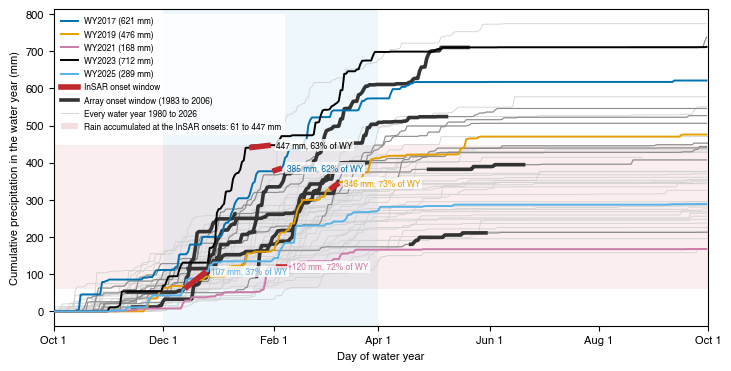

rain accumulated at the InSAR onsets: 61 to 447 mm, 37% to 73% of the water-year total; rule C: a >= 40 mm storm within 21 d of all 5 (P chance 0.02)


In [17]:
# [34]
fig, ax = plt.subplots(figsize=(7.2, 3.6), constrained_layout=True)
ax.axvspan(*wet_dowy, color="#56B4E9", alpha=0.10, lw=0)
# the band of accumulated rain at the InSAR onsets (window start to window end)
cum_lo, cum_hi = float(insar_rain.cum_at_lo.min()), float(insar_rain.cum_at_hi.max())
ax.axhspan(cum_lo, cum_hi, color="#C1272D", alpha=0.08, lw=0)
# every water year
for wy in range(wy_years[0], wy_years[1] + 1):
    this_year = wy_series(wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.82", lw=0.6, zorder=1)
# the array event years (dense era), onset window as a dark segment
for event in aa_rain.itertuples():
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.55", lw=0.8, zorder=2)
    segment = this_year[(this_year.dowy >= event.dowy_lo) & (this_year.dowy <= event.dowy_hi)]
    ax.plot(segment.dowy, segment.cum, "-", color="0.2", lw=2.6, solid_capstyle="butt", zorder=3)
# the InSAR event years in colour, onset window as a thick red segment, labelled by water year
event_colours = ["#0072B2", "#E69F00", "#CC79A7", "#000000", "#56B4E9"][:len(insar_rain)]   # Okabe-Ito, no green (Dani)
assert len(event_colours) == len(insar_rain), "more InSAR events than distinct colours"
for colour, event in zip(event_colours, insar_rain.itertuples()):
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color=colour, lw=1.4, zorder=4, label=f"WY{event.wy} ({event.wy_total_mm:.0f} mm)")
    ax.plot([event.dowy_lo, event.dowy_hi], [event.cum_at_lo, event.cum_at_hi], "-", color="#C1272D", lw=4, solid_capstyle="butt", zorder=5)
    ax.text(event.dowy_hi + 3, event.cum_at_hi, f"{event.cum_at_hi:.0f} mm, {event.frac_at_hi:.0%} of WY", fontsize=6, color=colour, va="center", zorder=6,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_xlim(1, 366)
ax.set_xticks([1, 62, 124, 182, 244, 305, 366])
ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("Cumulative precipitation in the water year (mm)")
ax.set_xlabel("Day of water year")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [Line2D([], [], color="#C1272D", lw=4, label="InSAR onset window"),
                                                       Line2D([], [], color="0.2", lw=2.6, label="Array onset window (1983 to 2006)"),
                                                       Line2D([], [], color="0.82", lw=0.6, label=f"Every water year {wy_years[0]} to {wy_years[1]}"),
                                                       plt.Rectangle((0, 0), 1, 1, facecolor="#C1272D", alpha=0.15, edgecolor="none", label=f"Rain accumulated at the InSAR onsets: {cum_lo:.0f} to {cum_hi:.0f} mm")],
          fontsize=6, loc="upper left")
f_cumulative = os.path.join(fig_dir, "figS_wy_cumulative_rain_onsets.png")
fig.savefig(f_cumulative, dpi=300)
fig.savefig(f_cumulative.replace(".png", ".pdf"))
print("Saved figure to:", f_cumulative)
plt.show()
print(f"rain accumulated at the InSAR onsets: {cum_lo:.0f} to {cum_hi:.0f} mm, {insar_rain.frac_at_hi.min():.0%} to {insar_rain.frac_at_hi.max():.0%} of the water-year total; "
      f"rule C: a >= {best_rule_c.Z:.0f} mm storm within {best_rule_c.X:.0f} d of all 5 (P chance {best_rule_c.p_chance_all_insar:.2f})")

## [35] The prediction statement

Built from the numbers above in the format of the legacy run22, so the
statement the paper makes is generated, not typed.

In [18]:
# [36]
insar_forecast = forecasts[(forecasts.catalog == "A_insar") & (forecasts.ref == "data_end")].set_index("model")
array_forecast = forecasts[(forecasts.catalog == "B_aa_dense_noLP") & (forecasts.ref == "data_end")].set_index("model")
merged_forecast = forecasts[(forecasts.catalog == "C_merged") & (forecasts.ref == "data_end")].set_index("model")
statement_lines = [
    "TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 10; the wording is the legacy run22 template)",
    f"written {forecast_issue_date}; conditioned on no event through the last InSAR acquisition on both tracks, {data_end}; "
    f"data: OPERA DISP-S1 to {data_end}, HRKT alignment array to {aa_events.onset_hi.max():.2f}, "
    f"Fremont GHCN gauge to {rain.index[rain.prcp_mm.notna()].max().date()}", "",
    "LOCATION  Hayward fault, Tule Pond section (see notebook 04 for the measured extent)",
    f"MAGNITUDE surface slip {insar_events.amplitude_mm.min():.1f}-{insar_events.amplitude_mm.max():.1f} mm on the stack (five InSAR events; "
    f"95% CIs {insar_events.amp_lo.min():.1f}-{insar_events.amp_hi.max():.1f} mm), within one 6-12 d acquisition interval", "",
    "TIME WINDOW",
    f"  (1) InSAR clock alone ({n_intervals} intervals, mean {interval_mean_yr:.2f} yr, sd {interval_sd_yr * 365.25:.0f} d): next = last + mean = {ymd(next_onset_yr)}; "
    f"+/-1 sd {ymd(next_onset_yr - interval_sd_yr)}..{ymd(next_onset_yr + interval_sd_yr)}; "
    f"95% prediction interval (t, n={n_intervals}) {ymd(next_onset_yr - half_width_yr)}..{ymd(next_onset_yr + half_width_yr)}",
    f"      renewal models (BPT, bootstrap): 5-95% {insar_forecast.loc['bpt', 'q05']} .. {insar_forecast.loc['bpt', 'q95']}, median {insar_forecast.loc['bpt', 'q50']}; "
    f"P(WY2027 wet season) = {insar_forecast.loc['bpt', 'p_wet_season']:.2f}",
    f"  (2) 45-yr alignment-array record: dense era BPT 5-95% {array_forecast.loc['bpt', 'q05']} .. {array_forecast.loc['bpt', 'q95']}, median {array_forecast.loc['bpt', 'q50']}; "
    f"P(WY2027 wet season) = {array_forecast.loc['bpt', 'p_wet_season']:.2f}, P(by end 2027) = {array_forecast.loc['bpt', 'p_by_2027']:.2f}",
    f"      merged BPT 5-95% {merged_forecast.loc['bpt', 'q05']} .. {merged_forecast.loc['bpt', 'q95']}, median {merged_forecast.loc['bpt', 'q50']}; "
    f"P(WY2027 wet season) = {merged_forecast.loc['bpt', 'p_wet_season']:.2f}; Poisson null {merged_forecast.loc['exponential', 'p_wet_season']:.2f}",
    f"  (3) all five InSAR onsets fell {int(insar_rain.dowy_lo.min())}-{int(insar_rain.dowy_hi.max())} d into the water year "
    f"({dowy_label(insar_rain.dowy_lo.min())}-{dowy_label(insar_rain.dowy_hi.max())}), after {insar_rain.cum_at_lo.min():.0f}-{insar_rain.cum_at_hi.max():.0f} mm of WY rain "
    f"({insar_rain.frac_at_hi.min():.0%}-{insar_rain.frac_at_hi.max():.0%} of the WY total), in years spanning "
    f"P{(wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100:.0f}-P{(wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100:.0f} of the 1980-2025 WY-total distribution",
    (f"      rule C: a 3-day storm >= {best_rule_c.Z:.0f} mm within {best_rule_c.X:.0f} d before onset (5/5 InSAR, {best_rule_c.aa_hits:.0f}/9 AA); "
     f"such windows cover {best_rule_c.base_rate:.0%} of Dec-Mar days, P(5/5 by chance) = {best_rule_c.p_chance_all_insar:.2f}" if best_rule_c is not None else "      rule C: none"),
    f"      rules A and B do not tighten the window beyond the calendar spread ({calendar_spread} d)"]
with open(os.path.join(out_dir, "prediction_statement.txt"), "w") as fh:
    fh.write("\n".join(statement_lines) + "\n")
print("\n".join(statement_lines))

TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 10; the wording is the legacy run22 template)
written 2026-08-25; conditioned on no event through the last InSAR acquisition on both tracks, 2026-03-21; data: OPERA DISP-S1 to 2026-03-21, HRKT alignment array to 2023.86, Fremont GHCN gauge to 2026-08-21

LOCATION  Hayward fault, Tule Pond section (see notebook 04 for the measured extent)
MAGNITUDE surface slip 6.6-9.2 mm on the stack (five InSAR events; 95% CIs 5.9-10.3 mm), within one 6-12 d acquisition interval

TIME WINDOW
  (1) InSAR clock alone (4 intervals, mean 1.97 yr, sd 30 d): next = last + mean = 2026-12-15; +/-1 sd 2026-11-15..2027-01-14; 95% prediction interval (t, n=4) 2026-08-29..2027-04-02
      renewal models (BPT, bootstrap): 5-95% 2026-10-28 .. 2027-01-21, median 2026-12-08; P(WY2027 wet season) = 0.99
  (2) 45-yr alignment-array record: dense era BPT 5-95% 2026-05-16 .. 2029-11-22, median 2027-05-12; P(WY2027 wet season) = 0.27, P(by end 2027) = 0.72


## [37] Supplementary figure: the rainfall conditioning

WY accumulation with the onsets; the lag after each rule A threshold; onset
day against the day the best rule A threshold was crossed.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-30/figS_precip_conditioning_storm3d_bestY125mm.png


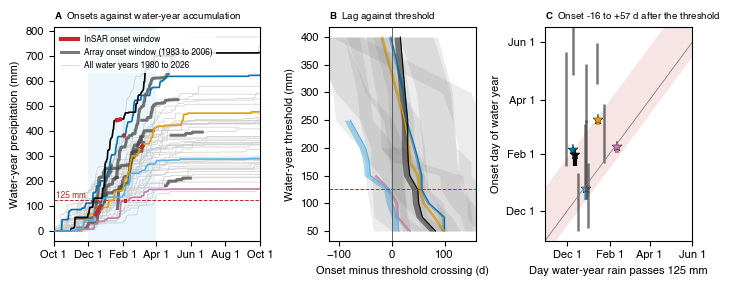

In [19]:
# [38]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9), width_ratios=[1.4, 1.0, 1.0])
event_colours = ["#0072B2", "#E69F00", "#CC79A7", "#000000", "#56B4E9"][:len(insar_rain)]   # Okabe-Ito, no green (Dani)
assert len(event_colours) == len(insar_rain), "more InSAR events than distinct colours"
# a) every water year's accumulation, the InSAR event years in colour, the onset windows as thick segments
ax = axes[0]
ax.axvspan(*wet_dowy, color="#56B4E9", alpha=0.12, lw=0)
for wy in range(wy_years[0], wy_years[1] + 1):
    this_year = wy_series(wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.8", lw=0.5, zorder=1)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color=colour, lw=1.2, zorder=3, label=f"WY{event.wy}")
    ax.plot([event.dowy_lo, event.dowy_hi], [event.cum_at_lo, event.cum_at_hi], "-", color="#C1272D", lw=3, solid_capstyle="butt", zorder=4)
for event in aa_rain.itertuples():
    this_year = wy_series(event.wy)
    segment = this_year[(this_year.dowy >= event.dowy_lo) & (this_year.dowy <= event.dowy_hi)]
    ax.plot(segment.dowy, segment.cum, "-", color="0.25", lw=2.2, alpha=0.7, zorder=2)
ax.axhline(best_rule_a.thr, color="#C1272D", lw=0.7, ls="--")
ax.text(5, best_rule_a.thr + 8, f"{best_rule_a.thr:.0f} mm", fontsize=6, color="#C1272D")
ax.set_xlim(1, 366)
ax.set_xticks([1, 62, 124, 182, 244, 305, 366])
ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("Water-year precipitation (mm)")
ax.legend(handles=[Line2D([], [], color="#C1272D", lw=3, label="InSAR onset window"),
                   Line2D([], [], color="0.25", lw=2.2, alpha=0.7, label="Array onset window (1983 to 2006)"),
                   Line2D([], [], color="0.8", lw=0.5, label="All water years 1980 to 2026")], fontsize=6, loc="upper left")
utils.panel_title(ax, "A", "Onsets against water-year accumulation")
# b) the lag of each onset after every rule A threshold
ax = axes[1]
thresholds = [score.thr for score in threshold_scores[threshold_scores.kind == "Y"].itertuples()]
for colour, event in zip(event_colours, insar_rain.itertuples()):
    lag_lo = [getattr(event, f"lagY{Y}_lo") for Y in thresholds]
    lag_hi = [getattr(event, f"lagY{Y}_hi") for Y in thresholds]
    ax.fill_betweenx(thresholds, lag_lo, lag_hi, color=colour, alpha=0.5, lw=0)
    ax.plot(lag_hi, thresholds, "-", color=colour, lw=0.8)
for event in aa_rain.itertuples():
    lag_lo = [getattr(event, f"lagY{Y}_lo") for Y in thresholds]
    lag_hi = [getattr(event, f"lagY{Y}_hi") for Y in thresholds]
    ax.fill_betweenx(thresholds, lag_lo, lag_hi, color="0.3", alpha=0.10, lw=0)
ax.axvline(0, color="0.3", lw=0.6)
ax.axhline(best_rule_a.thr, color="#C1272D", lw=0.7, ls="--")
ax.set_xlim(-120, 160)
ax.set_xlabel("Onset minus threshold crossing (d)")
ax.set_ylabel("Water-year threshold (mm)")
utils.panel_title(ax, "B", "Lag against threshold")
# c) onset day against the day the best rule A threshold was crossed
ax = axes[2]
best_Y = int(best_rule_a.thr)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    crossing_day = event.dowy_hi - getattr(event, f"lagY{best_Y}_hi")
    ax.plot([crossing_day, crossing_day], [event.dowy_lo, event.dowy_hi], "-", color=colour, lw=3, solid_capstyle="butt")
    ax.plot(crossing_day, event.dowy_hi, "*", color=colour, ms=8, mec="k", mew=0.3)
for event in aa_rain.itertuples():
    lag = getattr(event, f"lagY{best_Y}_hi")
    if np.isfinite(lag):
        crossing_day = event.dowy_hi - lag
        ax.plot([crossing_day, crossing_day], [event.dowy_lo, event.dowy_hi], "-", color="0.25", lw=1.8, alpha=0.7, solid_capstyle="butt")
diagonal = np.array([1, 366])
ax.plot(diagonal, diagonal, "-", color="0.5", lw=0.6)
ax.fill_between(diagonal, diagonal + best_rule_a.insar_lag_min, diagonal + best_rule_a.insar_lag_max, color="#C1272D", alpha=0.12, lw=0)
ax.set_xlim(30, 220)
ax.set_ylim(30, 260)
ticks, tick_labels = [62, 124, 182, 244], ["Dec 1", "Feb 1", "Apr 1", "Jun 1"]
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels)
ax.set_xlabel(f"Day water-year rain passes {best_Y} mm")
ax.set_ylabel("Onset day of water year")
utils.panel_title(ax, "C", f"Onset {best_rule_a.insar_lag_min:+.0f} to {best_rule_a.insar_lag_max:+.0f} d after the threshold")
fig.tight_layout()
f_conditioning = os.path.join(fig_dir, f"figS_precip_conditioning_storm{storm_days}d_bestY{best_Y}mm.png")
fig.savefig(f_conditioning, dpi=300)
fig.savefig(f_conditioning.replace(".png", ".pdf"))
print("Saved figure to:", f_conditioning)
plt.show()

## [39] REGISTER

In [20]:
# [40]
sidecar = REG.sidecar("10_forecast", stats_lines + ["", *statement_lines])
REG.register("10_issue_date", forecast_issue_date, "date", 0, where="P10, M9", cell="constants", sidecar=sidecar)
REG.register("10_data_end", data_end, "date", 0, where="P10, M9", cell="load", sidecar=sidecar)
REG.register("10_insar_interval_mean_yr", interval_mean_yr, "yr", 2, where="P10", cell="clock", sidecar=sidecar)
REG.register("10_insar_interval_sd_d", interval_sd_yr * 365.25, "d", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("10_insar_interval_sd_ci_lo_d", sd_ci_days[0], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("10_insar_interval_sd_ci_hi_d", sd_ci_days[1], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("10_insar_cov", interval_sd_yr / interval_mean_yr, "1", 2, where="P10", cell="clock", sidecar=sidecar)
REG.register("10_next_clock_date", ymd(next_onset_yr), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
REG.register("10_next_1sd_lo", ymd(next_onset_yr - interval_sd_yr), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("10_next_1sd_hi", ymd(next_onset_yr + interval_sd_yr), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("10_pi95_lo", ymd(next_onset_yr - half_width_yr), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
REG.register("10_pi95_hi", ymd(next_onset_yr + half_width_yr), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
for cat_name, key in (("A_insar", "insar"), ("B_aa_dense", "aa_dense"), ("B_aa_dense_noLP", "aa_dense_nolp"), ("C_merged", "merged")):
    issue = forecasts[(forecasts.catalog == cat_name) & (forecasts.ref == "data_end")].set_index("model")
    for model in ("bpt", "lognormal", "weibull", "exponential"):
        REG.register(f"10_{key}_{model}_q05", issue.loc[model, "q05"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"10_{key}_{model}_q50", issue.loc[model, "q50"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"10_{key}_{model}_q95", issue.loc[model, "q95"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"10_{key}_{model}_p_wet_wy2027", issue.loc[model, "p_wet_season"], "1", 2, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"10_{key}_{model}_p_by_end_2027", issue.loc[model, "p_by_2027"], "1", 2, where="P10", cell="forecast", sidecar=sidecar)
        REG.register(f"10_{key}_{model}_daicc", issue.loc[model, "daicc"], "1", 2, where="M9", cell="forecast", sidecar=sidecar)
    REG.register(f"10_{key}_n_intervals", int(issue.n_intervals.iloc[0]), "count", 0, where="M9", cell="forecast", sidecar=sidecar)
    REG.register(f"10_{key}_interval_mean_yr", float(issue.loc["bpt", "mean_yr"]), "yr", 2, where="P10", cell="forecast", sidecar=sidecar)
    REG.register(f"10_{key}_interval_cov", float(issue.loc["bpt", "cov"]), "1", 2, where="P10", cell="forecast", sidecar=sidecar)
REG.register("10_onset_dowy_min", int(insar_rain.dowy_lo.min()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_onset_dowy_max", int(insar_rain.dowy_hi.max()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_onset_earliest", dowy_label(insar_rain.dowy_lo.min()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_onset_latest", dowy_label(insar_rain.dowy_hi.max()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_onset_calendar_spread_d", calendar_spread, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_wy_total_min_mm", insar_rain.wy_total_mm.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_wy_total_max_mm", insar_rain.wy_total_mm.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_wy_percentile_min", (wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_wy_percentile_max", (wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_cum_at_onset_min_mm", insar_rain.cum_at_lo.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_cum_at_onset_max_mm", insar_rain.cum_at_hi.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_frac_at_onset_min", insar_rain.frac_at_hi.min(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_frac_at_onset_max", insar_rain.frac_at_hi.max(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_best_Y_mm", best_rule_a.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_lag_min_d", best_rule_a.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_lag_max_d", best_rule_a.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_best_Z_mm", best_rule_b.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_lag_min_d", best_rule_b.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_lag_max_d", best_rule_b.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
if best_rule_c is not None:
    REG.register("10_ruleC_Z_mm", best_rule_c.Z, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("10_ruleC_X_d", best_rule_c.X, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("10_ruleC_insar_hits", best_rule_c.insar_hits, "count", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("10_ruleC_aa_hits", best_rule_c.aa_hits, "count", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("10_ruleC_base_rate", best_rule_c.base_rate, "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("10_ruleC_p_chance", best_rule_c.p_chance_all_insar, "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/10_forecast/10_forecast_stats.txt
  registered 10_issue_date = 2026-08-25 date  -> P10, M9


  registered 10_data_end = 2026-03-21 date  -> P10, M9
  registered 10_insar_interval_mean_yr = 1.97 yr  -> P10
  registered 10_insar_interval_sd_d = 30 d  -> P10


  registered 10_insar_interval_sd_ci_lo_d = 17 d  -> M9
  registered 10_insar_interval_sd_ci_hi_d = 113 d  -> M9


  registered 10_insar_cov = 0.04 1  -> P10
  registered 10_next_clock_date = 2026-12-15 date  -> P10, Fig4
  registered 10_next_1sd_lo = 2026-11-15 date  -> P10


  registered 10_next_1sd_hi = 2027-01-14 date  -> P10
  registered 10_pi95_lo = 2026-08-29 date  -> P10, Fig4


  registered 10_pi95_hi = 2027-04-02 date  -> P10, Fig4
  registered 10_insar_bpt_q05 = 2026-10-28 date  -> P10, Fig4
  registered 10_insar_bpt_q50 = 2026-12-08 date  -> P10, Fig4


... (52 outputs left out)

  registered 10_ruleC_insar_hits = 5 count  -> P10


  registered 10_ruleC_aa_hits = 7 count  -> P10
  registered 10_ruleC_base_rate = 0.27 1  -> P10
  registered 10_ruleC_p_chance = 0.02 1  -> P10


Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'